In [314]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

In [315]:
df = pd.read_csv('/content/student_career_success_dataset.csv')
df.head(10)

,Student_ID,Age,Gender,University_Year,Major,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Academic_Performance,Programming_Skill,...,Teamwork,Problem_Solving,English_Proficiency,Interview_Score,Employability_Score,Placement_Status,Company_Tier,Career_Field,Placement_Mode,Starting_Salary_USD
0,ST000001,22,Male,Sophomore,Computer Science,86,21,3.28,Good,9,...,7,8,Advanced,72,231.70,Placed,Tier 1,Backend Developer,Campus Placement,72082
1,ST000002,20,Female,Freshman,Computer Science,64,18,2.53,Poor,6,...,6,5,Basic,59,157.45,Not Placed,No Company,Not Placed,Not Applicable,0
2,ST000003,23,Male,Senior,Information Technology,75,19,2.83,Average,8,...,8,7,Advanced,76,203.45,Placed,Tier 1,IT Support Engineer,Campus Placement,94898
3,ST000004,23,Female,Senior,Information Technology,80,19,2.80,Average,5,...,6,6,Intermediate,67,171.50,Not Placed,No Company,Not Placed,Not Applicable,0
4,ST000005,23,Female,Senior,Software Engineering,73,19,2.93,Average,9,...,8,9,Advanced,82,225.45,Placed,Tier 1,Software Engineer,Internship Conversion,85256
5,ST000006,21,Male,Senior,Computer Science,85,32,3.41,Good,9,...,6,9,Intermediate,72,210.05,Placed,Tier 1,Software Engineer,Off-Campus,109920
6,ST000007,21,Male,Junior,Artificial Intelligence,73,18,3.00,Average,8,...,6,6,Advanced,81,219.50,Placed,Tier 1,AI Engineer,Internship Conversion,85010
7,ST000008,23,Male,Freshman,Business Analytics,82,20,2.87,Average,4,...,6,4,Intermediate,57,160.35,Not Placed,No Company,Not Placed,Not Applicable,0
8,ST000009,23,Female,Freshman,Computer Science,82,39,3.48,Good,8,...,10,7,Advanced,100,241.20,Placed,Tier 1,Full Stack Developer,Campus Placement,96175
9,ST000010,30,Male,Junior,Information Technology,72,18,2.85,Average,5,...,6,5,Advanced,56,166.65,Not Placed,No Company,Not Placed,Not Applicable,0


# Data properties

In [316]:
df.shape

(50000, 29)

In [317]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'University_Year', 'Major',
       'Attendance_Percentage', 'Study_Hours_Per_Week', 'CGPA',
       'Academic_Performance', 'Programming_Skill', 'Projects_Completed',
       'Certifications', 'Hackathons', 'GitHub_Profile', 'Internships',
       'Leadership_Experience', 'LinkedIn_Profile', 'Resume_Score',
       'Communication_Skills', 'Teamwork', 'Problem_Solving',
       'English_Proficiency', 'Interview_Score', 'Employability_Score',
       'Placement_Status', 'Company_Tier', 'Career_Field', 'Placement_Mode',
       'Starting_Salary_USD'],
      dtype='object')

In [318]:
df.isna().sum()

,0
Student_ID,0
Age,0
Gender,0
University_Year,0
Major,0
Attendance_Percentage,0
Study_Hours_Per_Week,0
CGPA,0
Academic_Performance,0
Programming_Skill,0


In [319]:
df.dtypes

,0
Student_ID,object
Age,int64
Gender,object
University_Year,object
Major,object
Attendance_Percentage,int64
Study_Hours_Per_Week,int64
CGPA,float64
Academic_Performance,object
Programming_Skill,int64


# DF Manipualtion


In [320]:
df = df.iloc[:,:-4]


## Drop unwated columns

In [321]:
df.drop('Student_ID',axis=1,inplace=True)

In [322]:
df

,Age,Gender,University_Year,Major,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Academic_Performance,Programming_Skill,Projects_Completed,...,Leadership_Experience,LinkedIn_Profile,Resume_Score,Communication_Skills,Teamwork,Problem_Solving,English_Proficiency,Interview_Score,Employability_Score,Placement_Status
0,22,Male,Sophomore,Computer Science,86,21,3.28,Good,9,10,...,No,No,100,9,7,8,Advanced,72,231.70,Placed
1,20,Female,Freshman,Computer Science,64,18,2.53,Poor,6,6,...,No,Yes,80,5,6,5,Basic,59,157.45,Not Placed
2,23,Male,Senior,Information Technology,75,19,2.83,Average,8,9,...,Yes,No,100,7,8,7,Advanced,76,203.45,Placed
3,23,Female,Senior,Information Technology,80,19,2.80,Average,5,6,...,No,Yes,85,6,6,6,Intermediate,67,171.50,Not Placed
4,23,Female,Senior,Software Engineering,73,19,2.93,Average,9,10,...,Yes,Yes,100,10,8,9,Advanced,82,225.45,Placed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,22,Male,Sophomore,Software Engineering,76,13,2.92,Average,9,7,...,No,No,100,8,5,8,Advanced,86,224.80,Placed
49996,21,Male,Senior,Artificial Intelligence,84,21,2.90,Average,7,7,...,Yes,Yes,99,7,9,7,Intermediate,69,190.70,Not Placed
49997,20,Female,Junior,Software Engineering,86,25,3.31,Good,9,10,...,Yes,Yes,100,10,6,9,Advanced,86,243.15,Placed
49998,20,Male,Junior,Software Engineering,92,15,3.05,Average,10,12,...,No,No,100,7,6,10,Advanced,87,245.25,Placed


# Visualisation


<Axes: xlabel='Placement_Status', ylabel='count'>

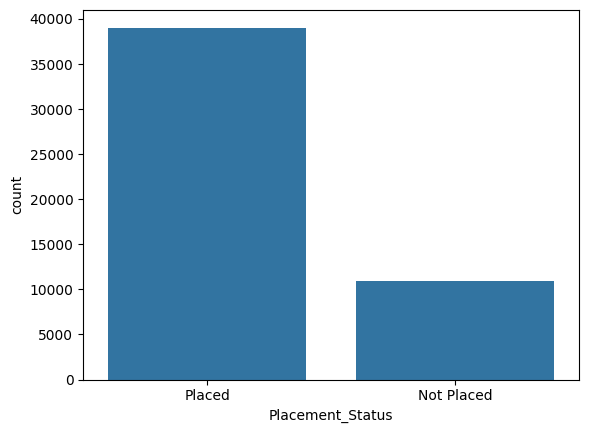

In [323]:
sns.countplot(data=df,x='Placement_Status')

In [324]:
df['Placement_Status'].value_counts()

,count
Placement_Status,
Placed,39040
Not Placed,10960


<Axes: xlabel='Gender', ylabel='count'>

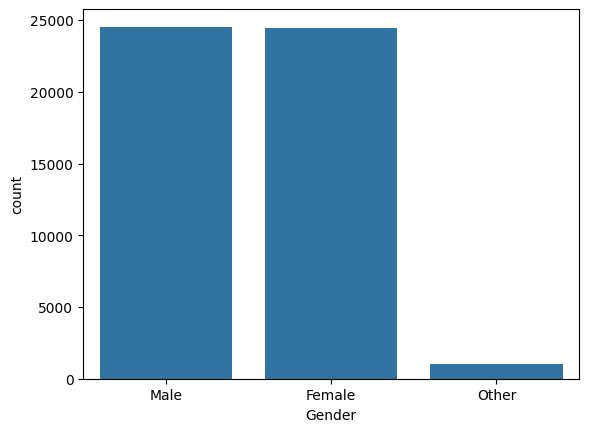

In [325]:
sns.countplot(data=df,x='Gender')

In [326]:
df['Gender'].value_counts()

,count
Gender,
Male,24533
Female,24465
Other,1002


In [327]:
pi = df.groupby('Major')['Major'].count()

plt

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

In [328]:
pi

,Major
Major,
Artificial Intelligence,7505
Business Analytics,4027
Computer Science,12407
Cybersecurity,4975
Data Science,6116
Electrical Engineering,2548
Information Technology,4906
Software Engineering,7516


([<matplotlib.patches.Wedge at 0x7ba7bf88aad0>,
 [Text(0.9799502403252348, 0.4996974349408997, 'Artificial Intelligence'),
  Text(0.4025581873737037, 1.0236927790008086, 'Business Analytics'),
  Text(-0.6726127698226427, 0.8703976458329336, 'Computer Science'),
  Text(-1.0823736159124473, -0.19613096536909835, 'Cybersecurity'),
  Text(-0.7041444949321245, -0.8450920247267651, 'Data Science'),
  Text(-0.16470150611629833, -1.0875998408803778, 'Electrical Engineering'),
  Text(0.34399134826714356, -1.0448301069156425, 'Information Technology'),
  Text(0.9796047002511884, -0.5003744910022687, 'Software Engineering')])

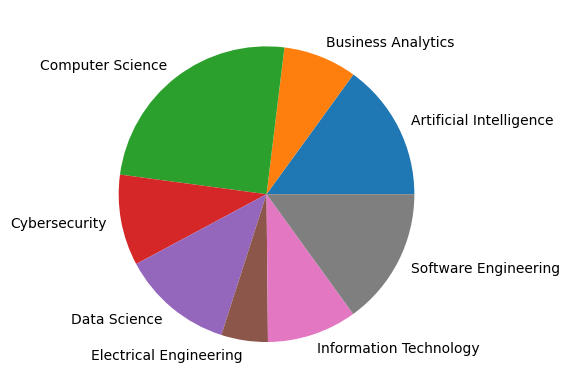

In [329]:
plt.pie(x=pi.values,labels=pi.index)

<Axes: >

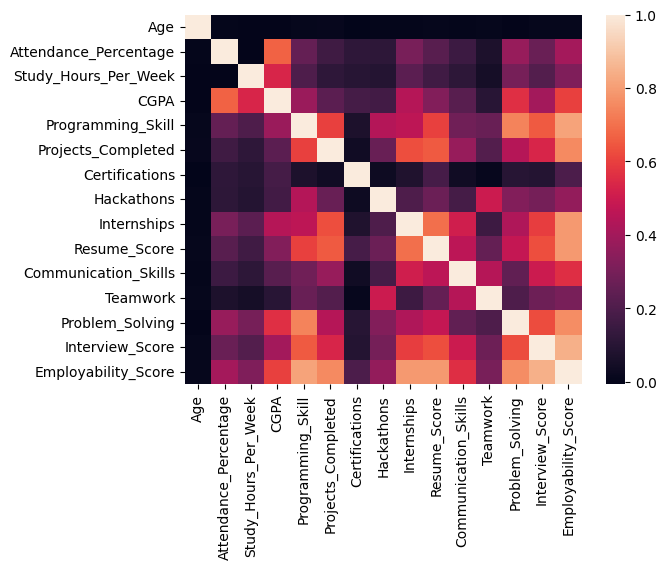

In [330]:
sns.heatmap(df.corr(numeric_only=True))

#Label Encoding

In [331]:
lab = LabelEncoder()
categorical_cols = ['Gender', 'University_Year', 'Major', 'Academic_Performance', 'GitHub_Profile', 'Leadership_Experience', 'LinkedIn_Profile', 'English_Proficiency']
obj = df.select_dtypes('object')
for i in obj:
  df[i] = lab.fit_transform(df[i])

Gender = lab.fit(df['Gender'])
University_Year = lab.fit(df['University_Year'])
Major = lab.fit(df['Major'])
Academic_Performance = lab.fit(df['Academic_Performance'])
GitHub_Profile = lab.fit(df['GitHub_Profile'])
Leadership_Experience = lab.fit(df['Leadership_Experience'])
LinkedIn_Profile = lab.fit(df['LinkedIn_Profile'])
English_Proficiency = lab.fit(df['English_Proficiency'])
Placement_Status = lab.fit(df['Placement_Status'])


In [332]:
df

,Age,Gender,University_Year,Major,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Academic_Performance,Programming_Skill,Projects_Completed,...,Leadership_Experience,LinkedIn_Profile,Resume_Score,Communication_Skills,Teamwork,Problem_Solving,English_Proficiency,Interview_Score,Employability_Score,Placement_Status
0,22,1,3,2,86,21,3.28,2,9,10,...,0,0,100,9,7,8,0,72,231.70,1
1,20,0,0,2,64,18,2.53,3,6,6,...,0,1,80,5,6,5,1,59,157.45,0
2,23,1,2,6,75,19,2.83,0,8,9,...,1,0,100,7,8,7,0,76,203.45,1
3,23,0,2,6,80,19,2.80,0,5,6,...,0,1,85,6,6,6,2,67,171.50,0
4,23,0,2,7,73,19,2.93,0,9,10,...,1,1,100,10,8,9,0,82,225.45,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,22,1,3,7,76,13,2.92,0,9,7,...,0,0,100,8,5,8,0,86,224.80,1
49996,21,1,2,0,84,21,2.90,0,7,7,...,1,1,99,7,9,7,2,69,190.70,0
49997,20,0,1,7,86,25,3.31,2,9,10,...,1,1,100,10,6,9,0,86,243.15,1
49998,20,1,1,7,92,15,3.05,0,10,12,...,0,0,100,7,6,10,0,87,245.25,1


In [333]:
df.isna().sum()

,0
Age,0
Gender,0
University_Year,0
Major,0
Attendance_Percentage,0
Study_Hours_Per_Week,0
CGPA,0
Academic_Performance,0
Programming_Skill,0
Projects_Completed,0


# Split features and labels

In [334]:
x =df.iloc[:,:-1].values
y = df.iloc[:,-1]

#train test split

In [335]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=.33,random_state=1)

# scalling

In [336]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

# Model Building

In [337]:
knn_model = KNeighborsClassifier()
knn_model.fit(x_train,y_train)


KNeighborsClassifier()

In [338]:
nb_model = GaussianNB()
nb_model.fit(x_train,y_train)

GaussianNB()

In [339]:
knn_y_pred = knn_model.predict(x_test)
nb_y_pred = nb_model.predict(x_test)

#Accuracy

#

In [340]:
ab = classification_report(y_test,knn_y_pred)
print(ab)

              precision    recall  f1-score   support

           0       0.55      0.34      0.42      3617
           1       0.83      0.92      0.88     12883

    accuracy                           0.80     16500
   macro avg       0.69      0.63      0.65     16500
weighted avg       0.77      0.80      0.78     16500



In [341]:
score = accuracy_score(y_test,knn_y_pred)
print(score)

0.7955151515151515


In [342]:
ab1 = classification_report(y_test,nb_y_pred)
print(ab)

              precision    recall  f1-score   support

           0       0.55      0.34      0.42      3617
           1       0.83      0.92      0.88     12883

    accuracy                           0.80     16500
   macro avg       0.69      0.63      0.65     16500
weighted avg       0.77      0.80      0.78     16500



In [343]:
score = accuracy_score(y_test,nb_y_pred)
print(score)

0.7853939393939394


In [344]:
import joblib

joblib.dump(knn_model, 'knn_model.pkt')
joblib.dump(nb_model,'nb_model.pkt')
joblib.dump(scaler,'scaler.pkt')

categorical_cols = ['Gender', 'University_Year', 'Major', 'Academic_Performance', 'GitHub_Profile', 'Leadership_Experience', 'LinkedIn_Profile', 'English_Proficiency']
for col in categorical_cols:
  joblib.dump(col,f'{col}.pkt')
  print(col)

Placement_Status
Placement_Status
Placement_Status
Placement_Status
Placement_Status
Placement_Status
Placement_Status
Placement_Status
